# Actividad 5 — Versión final de ejecución y evidencias

Incluye evaluación exploratoria de umbrales, importancia por permutación, registro MLflow SQLite, modelos portables y verificación del ZIP. Los resultados deben obtenerse ejecutando todas las celdas en Google Colab.


In [ ]:
%pip -q install "mlflow>=2.15,<4" "kagglehub>=0.3" "scikit-learn>=1.4,<1.9" pandas numpy matplotlib seaborn scipy joblib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 81.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [ ]:
from pathlib import Path
import os, sys, json, hashlib, platform, shutil, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
import mlflow, mlflow.sklearn, joblib
SEED=42
np.random.seed(SEED)
ROOT=Path.cwd()/"Actividad5"
RAW=ROOT/'datos'/'datos_ini'; CLEAN=ROOT/'datos'/'datos_limp'; FIG=ROOT/'evidencias'; TRACK=ROOT/'mlruns'
for d in (RAW,CLEAN,FIG,TRACK): d.mkdir(parents=True,exist_ok=True)
print('Python:',sys.version.split()[0], '| sklearn:',__import__('sklearn').__version__, '| mlflow:',mlflow.__version__)
print('Directorio:',ROOT)

Python: 3.13.15 | sklearn: 1.6.1 | mlflow: 3.17.1
Directorio: /content/Actividad5


In [ ]:
CSV=RAW/'churn_original.csv'
if not CSV.exists():
    try:
        import kagglehub
        source=Path(kagglehub.dataset_download('shantanudhakadd/bank-customer-churn-prediction'))
        candidates=list(source.rglob('*.csv'))
        if not candidates: raise FileNotFoundError('La descarga no contiene CSV')
        selected=next((f for f in candidates if 'churn' in f.name.lower()),candidates[0])
        shutil.copy2(selected,CSV)
        print('Archivo descargado:',selected)
    except Exception as exc:
        print('Descarga automática no disponible:',repr(exc))
        try:
            from google.colab import files
            print('Selecciona el CSV descargado manualmente desde Kaggle.')
            uploaded=files.upload()
            if not uploaded: raise RuntimeError('No se cargó archivo')
            fname=next(iter(uploaded))
            CSV.write_bytes(uploaded[fname])
        except ImportError:
            raise RuntimeError(f'Descarga manual: coloca el CSV en {CSV} y vuelve a ejecutar.') from exc
raw=pd.read_csv(CSV)
print('Dimensiones:',raw.shape,'| columnas:',raw.columns.tolist())
display(raw.head())
print('SHA256:',hashlib.sha256(CSV.read_bytes()).hexdigest())

Using Colab cache for faster access to the 'bank-customer-churn-prediction' dataset.
Archivo descargado: /kaggle/input/bank-customer-churn-prediction/Churn_Modelling.csv
Dimensiones: (10000, 14) | columnas: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


SHA256: 3996cd1fa372e0db0cd9c0ebac35bbd4e8e3c65fb942bb010c826e7b1eeef0a0


In [ ]:
assert 'Exited' in raw.columns, 'No existe la variable objetivo Exited. Verifica el dataset.'
assert set(raw['Exited'].dropna().unique()).issubset({0,1}), 'Exited debe ser binaria (0,1).'
audit=pd.DataFrame({'tipo':raw.dtypes.astype(str),'nulos':raw.isna().sum(),'porcentaje_nulos':(raw.isna().mean()*100).round(2),'unicos':raw.nunique(dropna=False)})
display(audit)
print('Filas duplicadas exactas:',raw.duplicated().sum())
print('Balance de clases:');display(raw['Exited'].value_counts(dropna=False).rename('frecuencia'))
# Evitar que identificadores o nombres personales participen como predictores.
DROP=[c for c in ['RowNumber','CustomerId','Surname'] if c in raw.columns]
clean=raw.drop_duplicates().drop(columns=DROP).copy()
clean=clean.dropna(subset=['Exited'])
clean['Exited']=clean['Exited'].astype(int)
# No se eliminan automáticamente valores atípicos: pueden representar casos legítimos.
assert clean['Exited'].nunique()==2, 'Se requieren ambas clases para entrenar.'
CLEAN_CSV=CLEAN/'churn_limpio_v1.csv'; clean.to_csv(CLEAN_CSV,index=False)
metadata={'version':'v1','dataset_origen':'Kaggle: shantanudhakadd/bank-customer-churn-prediction',
          'sha256_original':hashlib.sha256(CSV.read_bytes()).hexdigest(),
          'sha256_limpio':hashlib.sha256(CLEAN_CSV.read_bytes()).hexdigest(),
          'filas_originales':len(raw),'filas_limpias':len(clean),
          'duplicados_eliminados':int(raw.duplicated().sum()),'columnas_excluidas':DROP,
          'criterio_nulos':'Imputación dentro del pipeline ajustado solo con entrenamiento'}
(CLEAN/'metadata_v1.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(metadata,indent=2,ensure_ascii=False))

,tipo,nulos,porcentaje_nulos,unicos
RowNumber,int64,0,0.0,10000
CustomerId,int64,0,0.0,10000
Surname,object,0,0.0,2932
CreditScore,int64,0,0.0,460
Geography,object,0,0.0,3
Gender,object,0,0.0,2
Age,int64,0,0.0,70
Tenure,int64,0,0.0,11
Balance,float64,0,0.0,6382
NumOfProducts,int64,0,0.0,4


Filas duplicadas exactas: 0
Balance de clases:


,frecuencia
Exited,
0,7963
1,2037


{
  "version": "v1",
  "dataset_origen": "Kaggle: shantanudhakadd/bank-customer-churn-prediction",
  "sha256_original": "3996cd1fa372e0db0cd9c0ebac35bbd4e8e3c65fb942bb010c826e7b1eeef0a0",
  "sha256_limpio": "7ea085af2bf7f8a47b584daf7f646d8dba0d8296eb8171fa46c4734f0f74e7eb",
  "filas_originales": 10000,
  "filas_limpias": 10000,
  "duplicados_eliminados": 0,
  "columnas_excluidas": [
    "RowNumber",
    "CustomerId",
    "Surname"
  ],
  "criterio_nulos": "Imputación dentro del pipeline ajustado solo con entrenamiento"
}


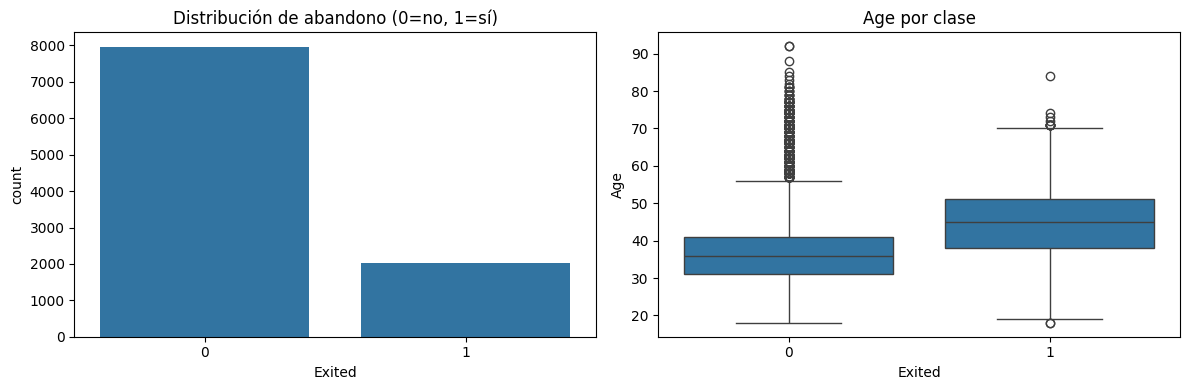

Interpretación pendiente: describir desequilibrio de clases y valores extremos observados, sin asumir que son errores.


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=clean,x='Exited',ax=axes[0]);axes[0].set_title('Distribución de abandono (0=no, 1=sí)')
num=clean.select_dtypes(include='number').drop(columns=['Exited'],errors='ignore')
if len(num.columns):
    col='Age' if 'Age' in num.columns else num.columns[0]
    sns.boxplot(data=clean,x='Exited',y=col,ax=axes[1]);axes[1].set_title(f'{col} por clase')
else: axes[1].text(.1,.5,'Sin predictores numéricos')
plt.tight_layout();plt.savefig(FIG/'01_calidad_datos.png',dpi=160);plt.show()
print('Interpretación pendiente: describir desequilibrio de clases y valores extremos observados, sin asumir que son errores.')

In [ ]:
X=clean.drop(columns=['Exited']); y=clean['Exited']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
numeric=X_train.select_dtypes(include=np.number).columns.tolist()
categorical=X_train.select_dtypes(exclude=np.number).columns.tolist()
preprocess=ColumnTransformer([
    ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),numeric),
    ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                     ('onehot',OneHotEncoder(handle_unknown='ignore'))]),categorical)
],remainder='drop')
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Entrenamiento:',X_train.shape,'| prueba:',X_test.shape)
print('Numéricas:',numeric,'| categóricas:',categorical)
print('Distribución de entrenamiento:',y_train.value_counts(normalize=True).round(3).to_dict())

Entrenamiento: (8000, 10) | prueba: (2000, 10)
Numéricas: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'] | categóricas: ['Geography', 'Gender']
Distribución de entrenamiento: {0: 0.796, 1: 0.204}


In [ ]:
# MLflow con backend SQLite (compatible con MLflow reciente).
DB_PATH = ROOT / 'mlflow.db'
ARTIFACTS_DIR = ROOT / 'mlartifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri('sqlite:///' + str(DB_PATH.resolve()))
EXPERIMENT_NAME = 'Actividad5_Churn_Comparacion_v2'
client = mlflow.tracking.MlflowClient()
experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    exp_id = client.create_experiment(EXPERIMENT_NAME, artifact_location=ARTIFACTS_DIR.resolve().as_uri())
else:
    exp_id = experiment.experiment_id
    print('Ubicación de artefactos:', experiment.artifact_location)
mlflow.set_experiment(EXPERIMENT_NAME)
models={
 'Regresion_Logistica':(LogisticRegression(max_iter=1500,random_state=SEED),{
     'model__C':[0.1,1.0,10.0],'model__class_weight':[None,'balanced']}),
 'Random_Forest':(RandomForestClassifier(random_state=SEED,n_jobs=-1),{
     'model__n_estimators':[100,200],'model__max_depth':[5,10,None],
     'model__min_samples_leaf':[1,3],'model__class_weight':[None,'balanced']})
}
results=[]; fitted={}
for name,(estimator,grid) in models.items():
    print('Entrenando:',name)
    pipe=Pipeline([('preprocess',preprocess),('model',estimator)])
    search=GridSearchCV(pipe,grid,scoring='roc_auc',cv=cv,n_jobs=-1,refit=True,return_train_score=True)
    with mlflow.start_run(run_name=name) as run:
        search.fit(X_train,y_train)
        best=search.best_estimator_; pred=best.predict(X_test); prob=best.predict_proba(X_test)[:,1]
        metrics={'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),
                 'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0),
                 'roc_auc':roc_auc_score(y_test,prob),'cv_roc_auc_mean':search.best_score_,
                 'cv_roc_auc_std':search.cv_results_['std_test_score'][search.best_index_]}
        mlflow.log_params({'algoritmo':name,'seed':SEED,'cv_folds':5,'test_size':.20,'dataset_sha256':metadata['sha256_limpio']})
        mlflow.log_params({k:str(v) for k,v in search.best_params_.items()})
        mlflow.log_metrics(metrics)
        mlflow.set_tags({'dataset_version':'v1','tipo_problema':'clasificacion_binaria'})
        model_info = mlflow.sklearn.log_model(
            sk_model=best,
            name='modelo',
            skops_trusted_types=[
                'numpy.dtype',
                'sklearn.compose._column_transformer._RemainderColsList',
                'sklearn.tree._tree.Tree'
            ]
        )
        # Copia portable adicional del pipeline para el ZIP de evidencias.
        # Solo cargar archivos joblib propios o de fuentes confiables.
        import joblib
        MODELS_DIR = ROOT / 'modelos'
        MODELS_DIR.mkdir(parents=True, exist_ok=True)
        local_model = MODELS_DIR / f'{name}.joblib'
        joblib.dump(best, local_model)
        mlflow.log_artifact(str(local_model), artifact_path='modelos_portables')
        mlflow.set_tag('modelo_uri', model_info.model_uri)
        mlflow.log_artifact(str(CLEAN/'metadata_v1.json'),artifact_path='datos')
        fig,ax=plt.subplots(figsize=(5,4));ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=ax,cmap='Blues')
        ax.set_title(name);fig.tight_layout();figpath=FIG/f'confusion_{name}.png';fig.savefig(figpath,dpi=150);plt.close(fig)
        mlflow.log_artifact(str(figpath),artifact_path='graficas')
        cvtable=pd.DataFrame(search.cv_results_);cvfile=FIG/f'gridsearch_{name}.csv';cvtable.to_csv(cvfile,index=False)
        mlflow.log_artifact(str(cvfile),artifact_path='busqueda')
        # Comprobar que el backend registre artefactos del experimento.
        artifacts = client.list_artifacts(run.info.run_id)
        print('Artefactos registrados:', [a.path for a in artifacts])
        row={'modelo':name,'run_id':run.info.run_id,**metrics,**{k:str(v) for k,v in search.best_params_.items()}}
        results.append(row);fitted[name]=(best,pred,prob)
        print(name,{k:round(v,4) for k,v in metrics.items()})
comparison=pd.DataFrame(results).sort_values('roc_auc',ascending=False)
display(comparison)
comparison.to_csv(FIG/'comparacion_modelos.csv',index=False)

2026/10/16 18:05:31 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 18:05:32 INFO mlflow.store.db.utils: Updating database tables


Entrenando: Regresion_Logistica
Artefactos registrados: ['busqueda', 'datos', 'graficas', 'modelos_portables']
Regresion_Logistica {'accuracy': 0.7135, 'precision': 0.3872, 'recall': 0.7002, 'f1': 0.4987, 'roc_auc': np.float64(0.7772), 'cv_roc_auc_mean': np.float64(0.7662), 'cv_roc_auc_std': np.float64(0.0205)}
Entrenando: Random_Forest
Artefactos registrados: ['busqueda', 'datos', 'graficas', 'modelos_portables']
Random_Forest {'accuracy': 0.8365, 'precision': 0.5862, 'recall': 0.6683, 'f1': 0.6246, 'roc_auc': np.float64(0.8614), 'cv_roc_auc_mean': np.float64(0.8574), 'cv_roc_auc_std': np.float64(0.0126)}


,modelo,run_id,accuracy,precision,recall,f1,roc_auc,cv_roc_auc_mean,cv_roc_auc_std,model__C,model__class_weight,model__max_depth,model__min_samples_leaf,model__n_estimators
1,Random_Forest,5546d4bf64c14f22bd3cfd939ee081ed,0.8365,0.586207,0.668305,0.624569,0.861421,0.857392,0.012643,NaN,balanced,10,3,200
0,Regresion_Logistica,b759514c0b1a4b13ba4b738c09465629,0.7135,0.387228,0.700246,0.498688,0.777165,0.766216,0.020533,1.0,balanced,NaN,NaN,NaN


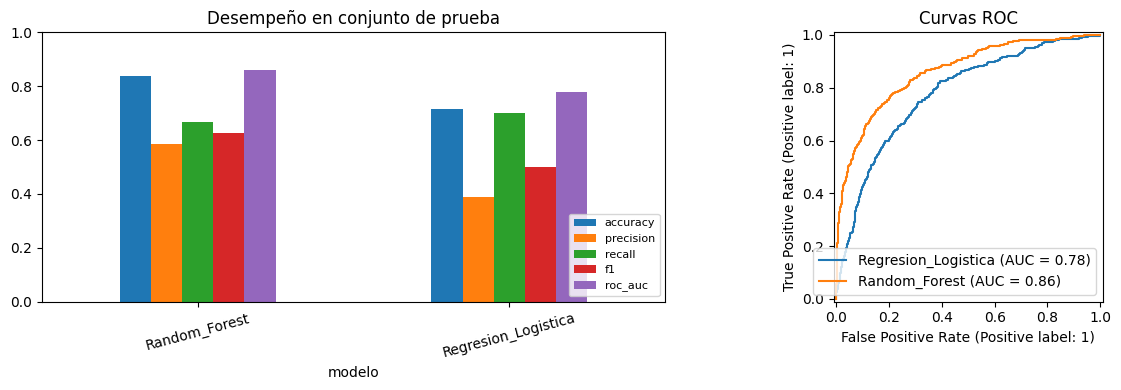

Diferencia ROC-AUC Regresion_Logistica menos Random_Forest: IC bootstrap 95% [-0.1045, -0.0638]
Advertencia: análisis exploratorio en una sola partición de prueba; no constituye validación externa.
Modelo líder por ROC-AUC: Random_Forest
La selección final también debe considerar recall, precisión, interpretabilidad y costo operativo.


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
comparison.set_index('modelo')[['accuracy','precision','recall','f1','roc_auc']].plot(kind='bar',ax=axes[0],ylim=(0,1),rot=15)
axes[0].set_title('Desempeño en conjunto de prueba');axes[0].legend(loc='lower right',fontsize=8)
for name,(_,pred,prob) in fitted.items():
    RocCurveDisplay.from_predictions(y_test,prob,name=name,ax=axes[1])
axes[1].set_title('Curvas ROC');plt.tight_layout();plt.savefig(FIG/'02_comparacion_modelos.png',dpi=160);plt.show()
# Comparación pareada mediante bootstrap sobre el mismo conjunto de prueba (exploratoria).
rng=np.random.default_rng(SEED); names=list(fitted)
if len(names)==2:
    p1=fitted[names[0]][2];p2=fitted[names[1]][2]; yy=y_test.to_numpy()
    diffs=[]
    for _ in range(1000):
        idx=rng.integers(0,len(yy),len(yy))
        if len(np.unique(yy[idx]))<2:continue
        diffs.append(roc_auc_score(yy[idx],p1[idx])-roc_auc_score(yy[idx],p2[idx]))
    ci=np.quantile(diffs,[.025,.975]);print(f'Diferencia ROC-AUC {names[0]} menos {names[1]}: IC bootstrap 95% [{ci[0]:.4f}, {ci[1]:.4f}]')
    print('Advertencia: análisis exploratorio en una sola partición de prueba; no constituye validación externa.')
print('Modelo líder por ROC-AUC:',comparison.iloc[0]['modelo'])
print('La selección final también debe considerar recall, precisión, interpretabilidad y costo operativo.')

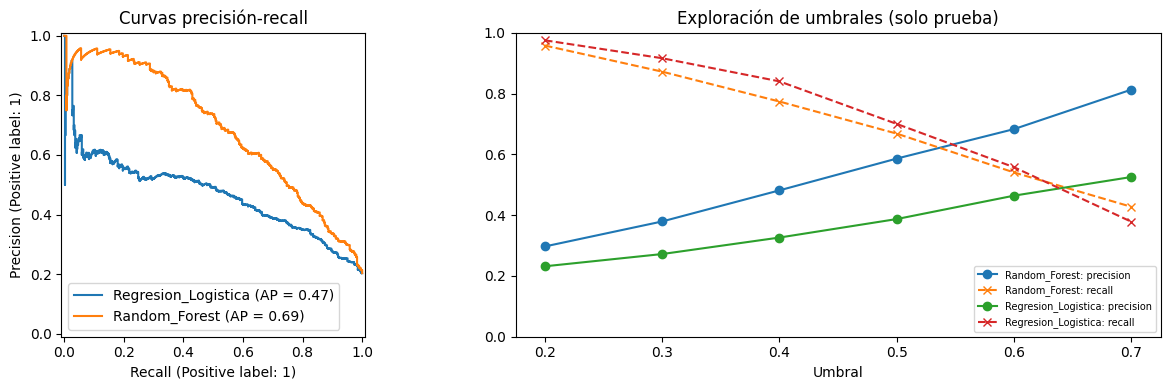

,modelo,umbral,precision,recall,f1,positivos_predichos
0,Regresion_Logistica,0.2,0.2318,0.9754,0.3745,1713
1,Regresion_Logistica,0.3,0.2721,0.9165,0.4196,1371
2,Regresion_Logistica,0.4,0.3263,0.8403,0.4701,1048
3,Regresion_Logistica,0.5,0.3872,0.7002,0.4987,736
4,Regresion_Logistica,0.6,0.4642,0.5577,0.5067,489
5,Regresion_Logistica,0.7,0.5256,0.3784,0.4400,293
6,Random_Forest,0.2,0.2970,0.9582,0.4535,1313
7,Random_Forest,0.3,0.3793,0.8722,0.5287,936
8,Random_Forest,0.4,0.4817,0.7740,0.5938,654
9,Random_Forest,0.5,0.5862,0.6683,0.6246,464


In [ ]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay
threshold_rows=[]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name,(_,pred,prob) in fitted.items():
    for threshold in [0.2,0.3,0.4,0.5,0.6,0.7]:
        p=(prob>=threshold).astype(int)
        threshold_rows.append({'modelo':name,'umbral':threshold,'precision':precision_score(y_test,p,zero_division=0),
                               'recall':recall_score(y_test,p,zero_division=0),'f1':f1_score(y_test,p,zero_division=0),
                               'positivos_predichos':int(p.sum())})
    PrecisionRecallDisplay.from_predictions(y_test,prob,name=name,ax=axes[0])
threshold_df=pd.DataFrame(threshold_rows)
for name,g in threshold_df.groupby('modelo'):
    axes[1].plot(g['umbral'],g['precision'],marker='o',label=f'{name}: precision')
    axes[1].plot(g['umbral'],g['recall'],marker='x',linestyle='--',label=f'{name}: recall')
axes[0].set_title('Curvas precisión-recall');axes[1].set_title('Exploración de umbrales (solo prueba)')
axes[1].set_xlabel('Umbral');axes[1].set_ylim(0,1);axes[1].legend(fontsize=7)
fig.tight_layout();fig.savefig(FIG/'03_umbral_precision_recall.png',dpi=160);plt.show()
display(threshold_df.round(4))
threshold_df.to_csv(FIG/'umbrales_exploratorios.csv',index=False)


,variable,importancia_media,desviacion
3,Age,0.1238,0.0064
6,NumOfProducts,0.1024,0.0100
5,Balance,0.0297,0.0051
8,IsActiveMember,0.0292,0.0031
1,Geography,0.0210,0.0016
2,Gender,0.0093,0.0028
9,EstimatedSalary,0.0002,0.0013
7,HasCrCard,-0.0002,0.0006
0,CreditScore,-0.0004,0.0008
4,Tenure,-0.0011,0.0009


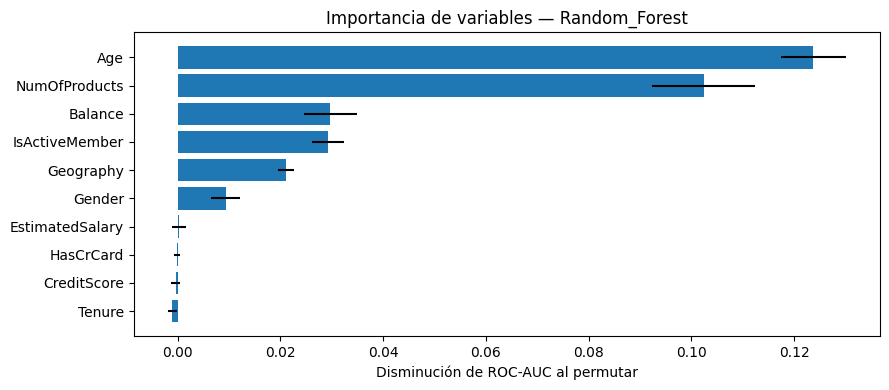

In [ ]:
from sklearn.inspection import permutation_importance
leader=comparison.iloc[0]['modelo']
leader_model=fitted[leader][0]
perm=permutation_importance(leader_model,X_test,y_test,scoring='roc_auc',n_repeats=8,random_state=SEED,n_jobs=-1)
importance=pd.DataFrame({'variable':X_test.columns,'importancia_media':perm.importances_mean,
                         'desviacion':perm.importances_std}).sort_values('importancia_media',ascending=False)
display(importance.round(4))
importance.to_csv(FIG/'importancia_permutacion.csv',index=False)
fig,ax=plt.subplots(figsize=(9,max(4,len(importance)*.38)))
ax.barh(importance['variable'][::-1],importance['importancia_media'][::-1],xerr=importance['desviacion'][::-1])
ax.set_xlabel('Disminución de ROC-AUC al permutar');ax.set_title(f'Importancia de variables — {leader}')
fig.tight_layout();fig.savefig(FIG/'04_importancia_variables.png',dpi=160);plt.show()


In [ ]:
from mlflow.tracking import MlflowClient
client= MlflowClient()
exp=client.get_experiment_by_name(EXPERIMENT_NAME)
assert exp is not None
print('Experimento:',exp.name,'| artefactos:',exp.artifact_location)
for run in client.search_runs([exp.experiment_id],max_results=50):
    if run.info.status!='FINISHED':continue
    items=client.list_artifacts(run.info.run_id)
    print(run.info.run_id[:10], 'métricas:',len(run.data.metrics),'parámetros:',len(run.data.params),
          'artefactos:',[(x.path,'directorio' if x.is_dir else 'archivo') for x in items])
    assert run.data.metrics, 'Faltan métricas'
    assert items, 'Faltan artefactos'
    paths = [x.path for x in items]
    assert 'modelos_portables' in paths, 'No aparece el modelo portable registrado'
    model_files = client.list_artifacts(run.info.run_id, 'modelos_portables')
    assert any(x.path.endswith('.joblib') for x in model_files), 'No hay archivo de modelo portable'
assert (ARTIFACTS_DIR.exists() and any(ARTIFACTS_DIR.rglob('*'))), 'No se encontraron artefactos físicos en el directorio'
assert len(list((ROOT/'modelos').glob('*.joblib'))) == 2, 'Faltan modelos locales para el ZIP'
print('Validación de artefactos y modelos portables: satisfactoria')


Experimento: Actividad5_Churn_Comparacion_v2 | artefactos: file:///content/Actividad5/mlartifacts
5546d4bf64 métricas: 7 parámetros: 9 artefactos: [('busqueda', 'directorio'), ('datos', 'directorio'), ('graficas', 'directorio'), ('modelos_portables', 'directorio')]
b759514c0b métricas: 7 parámetros: 7 artefactos: [('busqueda', 'directorio'), ('datos', 'directorio'), ('graficas', 'directorio'), ('modelos_portables', 'directorio')]
Validación de artefactos y modelos portables: satisfactoria


## 7. Exportación de evidencias y acceso a MLflow

In [ ]:
# Resumen y artefactos reproducibles
import zipfile
summary={'seed':SEED,'dataset_version':'v1','dataset_sha256':metadata['sha256_limpio'],
         'resultados':comparison.to_dict(orient='records'),'experimento_mlflow':EXPERIMENT_NAME,'modelo_lider':leader}
(FIG/'resumen_experimentos.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False,default=str),encoding='utf-8')
# Manifiesto de archivos para auditar el paquete exportado.
import hashlib
manifest=[]
for file in sorted(ROOT.rglob('*')):
    if file.is_file():
        manifest.append({'ruta':str(file.relative_to(ROOT)), 'bytes':file.stat().st_size,
                         'sha256':hashlib.sha256(file.read_bytes()).hexdigest()})
(FIG/'manifiesto_archivos.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
archive=shutil.make_archive(str(Path.cwd()/'Actividad5_evidencias'), 'zip',root_dir=ROOT)
print('ZIP de evidencias:',archive)
print('Base de datos MLflow:', DB_PATH)
print('Para abrir interfaz MLflow local: mlflow ui --backend-store-uri "'+mlflow.get_tracking_uri()+'"')
print('En Colab: descargar el ZIP; la interfaz MLflow local no se publica automáticamente.')
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Descarga manual desde la carpeta de trabajo:',archive)
with zipfile.ZipFile(archive) as z:
    assert any(p.startswith('modelos/') and p.endswith('.joblib') for p in z.namelist())
    assert any(p.endswith('mlflow.db') for p in z.namelist())
print('ZIP validado: incluye modelos portables y base de datos de MLflow')


ZIP de evidencias: /content/Actividad5_evidencias.zip
Base de datos MLflow: /content/Actividad5/mlflow.db
Para abrir interfaz MLflow local: mlflow ui --backend-store-uri "sqlite:////content/Actividad5/mlflow.db"
En Colab: descargar el ZIP; la interfaz MLflow local no se publica automáticamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ZIP validado: incluye modelos portables y base de datos de MLflow
